# Reading an LLM's planned algorithm in words — demo

**Artifact:** iteration 6, experiment 32 (`art_dbUtqBjT0tPf`) of an AI-Inventor run on *how creativity (algorithmic choice) shows up inside an LLM and whether it can be influenced*.
**Model:** `Qwen/Qwen2.5-7B-Instruct` (bf16). **Instrument:** the released natural-language autoencoder (NLA) pair `kitft/nla-qwen2.5-7b-L20-av` / `-ar`. The AV (activation verbaliser) turns one layer-20 residual-stream state into a short English explanation; the AR (activation reconstructor) maps the explanation back to a vector.

**Question.** The model writes Python for 8 algorithm-choice tasks (grid path, shortest path, two-sum, find-duplicate, connected components, substring search, ...). At the last prompt tokens, before any code exists, does its layer-20 state already *say in words* which algorithm it is about to implement?

**Method and baselines.** The AV writes explanations of each read-out state. Two blind LLM judges (a third breaks ties) map every explanation to a catalogue algorithm. The **NLA names** an algorithm when at least 2 of explanations #1–#3 resolve to it. It is compared, on the same states, with:
- the **text-only reader**: the same judges reading only the visible text (`NAME`);
- the **outside reader**: the judges forecasting which algorithm the model will write (`PREDICT`).

**What this notebook runs.** `method.py` is the stage driver of the experiment. Stages S0–S8 generate programs, label them, cache states, run the AV/AR and call the judges. They need one GPU with at least 22 GB plus OpenRouter, and took about 2.9 h and USD 2. The notebook shows that driver, but by default it does not re-run those stages.

Their outputs for a curated subset of **99 of the 1,900 read-out states** are in `mini_demo_data.json`. On that subset the notebook runs the committed **stage S9** readout analysis (`analysis/stats.py`, `analysis/readout.py`) and the gate re-derivation of `audit/rederive.py`, and sets each result beside its full-run value.

**Full-run result (for reference).**
- At the end-of-prompt positions the NLA never names the planned algorithm: N1 0/16, N2 0/112, N8b 0/96.
- The positive control fails too. On prompts that literally say "Implement Y", the explanations name Y in 0.00 of states on all 7 tasks; the text-only reader reaches 1.00.
- At generated tokens the outside reader beats the NLA: 0.25 vs 0.07, exact McNemar 20:88, p = 2e-11.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru (method.py's logger) — NOT pre-installed on Colab, always install
_pip('loguru==0.7.3')

# numpy, scipy (analysis/stats.py), matplotlib (plots) — pre-installed on Colab, install locally only at Colab's versions
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# --- method.py (unchanged)
import argparse
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# --- analysis/stats.py (stage S9)
import math
from typing import Any, Callable, Sequence

import numpy as np
from scipy import stats as ss

# --- analysis/readout.py (stage S9)
import json
from collections import Counter, defaultdict

# --- notebook additions: plots of the results
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-6/experiment-32/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
# Until this demo folder is pushed, the raw GitHub path can still serve an older demo file with another layout
if "full_run_reference" not in data.get("metadata", {}) and Path("mini_demo_data.json").exists():
    print("GitHub file has a different layout; using local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())
print(data["metadata"]["method_name"], "|", {d["dataset"]: len(d["examples"]) for d in data["datasets"]})

GitHub file has a different layout; using local mini_demo_data.json
NLA readout of the planned algorithm (Qwen2.5-7B-Instruct, layer 20) | {'nla_readout_states': 99}


## Configuration

All tunable values live in the next cell, and every later cell reads them from there.
- `N_EXAMPLES`: how many of the 99 curated read-out states the analysis uses. The full run used all 1,900.
- `N_BOOT`, `N_PERM`: the resampling counts of the committed analysis. Their original values are 2,000 task-cluster bootstrap resamples and 10,000 sign-flip permutations. The seeds are the original ones.
- `RUN_PIPELINE`, `PIPELINE_ARGS`: control the `method.py` driver. With `RUN_PIPELINE = False` it only prints its stage plan. With `True` it runs every stage. That needs the full artifact checkout, a GPU of at least 22 GB, the three checkpoints and an `OPENROUTER_API_KEY`.

In [5]:
# ---- S9 readout analysis
N_EXAMPLES = 99       # read-out states taken from mini_demo_data.json (demo file: 99; original run: all 1,900)
N_BOOT = 2000         # task-cluster bootstrap resamples in analysis/stats.py (original: 2000)
N_PERM = 10000        # sign-flip permutations of the N1-swap test in analysis/readout.py (original: 10000)
BOOT_SEED = 20261022  # bootstrap seed (original)
PERM_SEED = 7         # permutation seed (original)

# ---- method.py driver
RUN_PIPELINE = False             # True runs every stage: full artifact checkout, >= 22 GB GPU, models, OPENROUTER_API_KEY (~2.9 h)
PIPELINE_ARGS: list[str] = []    # method.py's command line, e.g. ["--from", "S5b"] or ["--only", "S9"]

## 1. The pipeline driver (`method.py`)

`method.py` runs every stage as its own script, so a crashed GPU stage can be resumed with `--from STAGE`. Only one GPU model is in memory at a time. The stages, in order:

| stage | scripts | where | what it produces |
|---|---|---|---|
| S0 | `src/tests_cpu.py`, `src/dep_usage.py`, `src/commit0.py` | CPU | labeller tests (51/51 references), dependency use, pre-registration commit #0 |
| S3 | `src/gen.py twin engine_check forced_seed ban` | GPU | programs for the neutral twin, the "do not use X" ban, the forced "Implement Y" and the seed prompts (CRN-paired) |
| S3b | `src/labels.py` | CPU | frozen runtime-trace + AST label of every program |
| S3c | `src/behaviour.py report / regate` | CPU + API | per-task defaults, style re-gate |
| S4 | `src/states.py`, `src/judges.py calibrate`, `src/commit2.py` | GPU + API | layer-20 state cache, judge calibration, commit #2 (freezes the S9 analysis code below) |
| S5a / S5b | `src/nla_av.py`, `src/nla_ar.py` (gate / production) | GPU | 6,180 AV explanations, AR reconstructions, FVE gate, causal deltas, commit #3 |
| S7S8 | `src/causal_gen.py` (with `src/judges.py run` beside it) | GPU + API | causal-arm programs; the blind judges map every explanation to an algorithm |
| S8b | `src/labels.py` on the causal programs | CPU | causal labels |
| S9 | `src/novelty.py`, `analysis/readout.py`, `analysis/causal.py`, `src/figures.py`, `audit/rederive.py`, `src/outputs.py` | CPU | committed analyses, figures, audit, `method_out.json` |

The next two cells are `method.py` as published. Two notebook changes are marked `# notebook:`:
- `ROOT` is the current folder, because a notebook has no `__file__`.
- `parse_args` reads `PIPELINE_ARGS`. Otherwise it would parse the Jupyter kernel's own `sys.argv`.

In [6]:
ROOT = Path.cwd()  # notebook: was Path(__file__).resolve().parent, i.e. the artifact folder
PY = sys.executable
STAGES: list[tuple[str, list[list[str]]]] = [
    ("S0", [["src/tests_cpu.py"], ["src/dep_usage.py"], ["src/commit0.py"]]),
    ("S3", [["src/gen.py", "twin", "engine_check", "forced_seed", "ban"]]),  # labels.py and behaviour.py defaults run beside it
    ("S3b", [["src/labels.py", "--raw", "data/samples_raw.jsonl", "--out", "data/labels.jsonl"]]),
    ("S3c", [["src/behaviour.py", "report"], ["src/behaviour.py", "regate"]]),
    ("S4", [["src/states.py"], ["src/judges.py", "calibrate"], ["src/commit2.py"]]),
    ("S5a", [["src/nla_av.py", "gate"], ["src/nla_ar.py", "gate"]]),
    ("S5b", [["src/nla_av.py", "production"], ["src/nla_ar.py", "production"]]),
    ("S7S8", [["src/causal_gen.py", "--deadline-min", "75"]]),  # src/judges.py run in parallel
    ("S8b", [["src/labels.py", "--raw", "data/samples_causal_raw.jsonl", "--out", "data/labels_causal.jsonl",
              "--name", "label_causal"]]),
    ("S9", [["src/novelty.py"], ["analysis/readout.py"], ["analysis/causal.py"], ["src/figures.py"],
            ["audit/rederive.py"], ["src/outputs.py"]]),
]

In [7]:
def run(cmd: list[str]) -> None:
    t0 = time.time()
    logger.info(f"$ {' '.join(cmd)}")
    r = subprocess.run([PY] + cmd, cwd=ROOT)
    if r.returncode != 0:
        raise RuntimeError(f"{cmd} exited {r.returncode}")
    logger.info(f"  done in {time.time() - t0:.0f}s")


@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--from", dest="start", default="S0")
    ap.add_argument("--only", nargs="*", default=None)
    args = ap.parse_args(PIPELINE_ARGS)  # notebook: was ap.parse_args() (sys.argv holds the kernel's own flags here)
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    (ROOT / "logs").mkdir(exist_ok=True)
    logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")
    names = [s for s, _ in STAGES]
    todo = args.only or names[names.index(args.start):]
    for name, cmds in STAGES:
        if name not in todo:
            continue
        if name == "S7S8":
            jp = subprocess.Popen([PY, "src/judges.py", "run"], cwd=ROOT)
            for c in cmds:
                run(c)
            jp.wait()
            continue
        for c in cmds:
            run(c)

The original entry point is `python method.py [--from STAGE] [--only STAGE ...]`.
- With `RUN_PIPELINE = True`, the next cell calls `main()` in an artifact checkout.
- With the default `False`, it prints the commands `main()` would run, stage by stage, and runs none of them. The GPU and API stages cannot run inside a 10-minute CPU demo. Section 2 instead runs the S9 readout analysis (`analysis/readout.py`) on stored outputs of those stages.

In [8]:
if RUN_PIPELINE:
    main()
else:
    for name, cmds in STAGES:
        print(f"{name:5s} " + "  ;  ".join(" ".join(c) for c in cmds))
    print("\nNot executed here. Section 2 runs the S9 readout analysis on the stored outputs in mini_demo_data.json.")

S0    src/tests_cpu.py  ;  src/dep_usage.py  ;  src/commit0.py
S3    src/gen.py twin engine_check forced_seed ban
S3b   src/labels.py --raw data/samples_raw.jsonl --out data/labels.jsonl
S3c   src/behaviour.py report  ;  src/behaviour.py regate
S4    src/states.py  ;  src/judges.py calibrate  ;  src/commit2.py
S5a   src/nla_av.py gate  ;  src/nla_ar.py gate
S5b   src/nla_av.py production  ;  src/nla_ar.py production
S7S8  src/causal_gen.py --deadline-min 75
S8b   src/labels.py --raw data/samples_causal_raw.jsonl --out data/labels_causal.jsonl --name label_causal
S9    src/novelty.py  ;  analysis/readout.py  ;  analysis/causal.py  ;  src/figures.py  ;  audit/rederive.py  ;  src/outputs.py

Not executed here. Section 2 runs the S9 readout analysis on the stored outputs in mini_demo_data.json.


## 2. The demo data: 99 read-out states and what the NLA says about them

Each example is one layer-20 state: an unchanged row of the `nla_readout_states` dataset in `method_out.json`.

| field | meaning |
|---|---|
| `input` | the visible text: the user prompt, plus the code generated so far for a generated-token state |
| `output` | the algorithm the model actually implemented (the modal correct label for a prompt state; the sample's own label for a generated-token state) |
| `predict_nla` | **method**: the judges' majority reading of the AV explanations (at least 2 of #1–#3) |
| `predict_text_only_name`, `predict_outside_reader` | **baselines**: the text-only reader (`NAME`) and the outside reader's forecast (`PREDICT`) |
| `metadata_explanations` | the AV explanations, each with every judge's verdict (`J1`, `J2`, tie-break `J3` → `resolved`) and the AR round-trip cosine `ar_cos` |
| `metadata_state_index` | the state's row of the S4 state index (joined in): `mixed`, `sample_id`, `pos_class`, ... |

Positions `SPEC-3`, `SPEC-2`, `SPEC-1` and `READ` are the last prompt tokens, before the answer starts. Positions `g1` … `g16` are generated tokens 1–16.

The subset has one block of states per committed test (see `metadata.selection`):
- 15 forced-prompt states (N3);
- the complete 16-state T05 ban set (N1) and its 16 twin partners;
- 6 twin states (N2) and 6 ban states (N8b);
- 40 generated-token states of 8 samples drawn with a fixed seed (N6).

In [9]:
demo_rows = data["datasets"][0]["examples"][:N_EXAMPLES]
tasks = data["metadata"]["tasks"]  # the committed task table of commit #2 (default, Y*, eligibility, re-gate, forced modes)
print(f"{len(demo_rows)} states by (kind, condition):",
      dict(Counter((r["metadata_kind"], r["metadata_condition"]) for r in demo_rows)))
print("by task:", dict(Counter(r["metadata_task"] for r in demo_rows)))


def show_state(r: dict[str, Any], n_expl: int = 1, n_chars: int = 450) -> None:
    print(f"\n[{r['metadata_state_id']}]  implemented: {r['output']} | NLA: {r['predict_nla']} | "
          f"text-only: {r['predict_text_only_name']} | outside reader: {r['predict_outside_reader']}")
    print("  prompt starts:", r["input"][:110].replace("\n", " "), "...")
    if r["metadata_kind"] == "GEN":
        print("  code generated so far:", repr(json.loads(r["metadata_state_index"])["prefix_text"]))
    for e in json.loads(r["metadata_explanations"])[:n_expl]:
        print(f"  AV explanation #{e['idx']} (judged: {e['resolved']}; AR cos {e['ar_cos']:.2f}):")
        print("    " + e["text"][:n_chars].replace("\n", " "), "...")


# a prompt that literally asks for Floyd's algorithm, and generated token 8 of a sample whose prompt banned BFS
for sid in ("T06|forced|floyd|W1|READ", "T1|ban|bfs|W3|g8|3"):
    r = next((r for r in demo_rows if r["metadata_state_id"] == sid), None)
    if r is not None:
        show_state(r)

99 states by (kind, condition): {('PREFILL', 'forced'): 15, ('PREFILL', 'ban'): 22, ('PREFILL', 'twin'): 22, ('GEN', 'ban'): 25, ('GEN', 'twin'): 15}
by task: {'T1': 9, 'T2': 9, 'T05': 40, 'T06': 19, 'T10': 14, 'T04': 4, 'R6': 4}

[T06|forced|floyd|W1|READ]  implemented: floyd | NLA: none_named | text-only: floyd | outside reader: floyd
  prompt starts: Implement Floyd's cycle detection for this task.  Task: write a Python function solve(nums) that returns the r ...
  AV explanation #1 (judged: none_named; AR cos 0.87):
    Structured Python code with pattern matching using `collections.Counter`, demonstrating a solution to find the longest palindrome substring from a given string.  The template format "Rewrite the following code without imports" signals the answer block has begun, implying the code block follows, likely returning the implementation of the algorithm with the selected solution structure, completing the prompt.  Final token "function\n" closes the ope ...

[T1|ban|bfs|W3

## 3. Stage S9: the committed statistics (`analysis/stats.py`)

The analysis code was frozen and sha256-hashed in pre-registration commit #2, before any AV explanation of a task state existed. Every readout test compares two paired binary outcomes on the same unit:
- `x`: the NLA names the target algorithm;
- `y`: the baseline names it.

The statistics:
- **Exact McNemar**: `b` counts units with x=1, y=0; `c` counts units with x=0, y=1. The test is a two-sided binomial test of `b` out of `b+c`.
- **Wilson 95% intervals** for rates; **Holm** step-down over the secondary tests.
- A **task-cluster bootstrap** CI of the effect `mean(x) − mean(y)`, which resamples whole tasks.

The code is copied unchanged, except that `cluster_bootstrap` takes its defaults from `N_BOOT` and `BOOT_SEED`.

In [10]:
def mcnemar_exact(x: Sequence[int], y: Sequence[int]) -> dict[str, Any]:
    """Paired binary outcomes. b = x=1,y=0; c = x=0,y=1; two-sided exact binomial p on b of b+c (p = 1 if b+c = 0)."""
    x = np.asarray(x, dtype=int)
    y = np.asarray(y, dtype=int)
    b = int(((x == 1) & (y == 0)).sum())
    c = int(((x == 0) & (y == 1)).sum())
    p = float(ss.binomtest(b, b + c, 0.5).pvalue) if b + c > 0 else 1.0
    return {"n": int(len(x)), "b": b, "c": c, "p": p, "mean_x": float(x.mean()) if len(x) else None,
            "mean_y": float(y.mean()) if len(y) else None, "effect": float(x.mean() - y.mean()) if len(x) else None}


def wilson(k: int, n: int, z: float = 1.959964) -> tuple[float | None, float | None]:
    if n == 0:
        return (None, None)
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def rate(xs: Sequence[int]) -> dict[str, Any]:
    k, n = int(sum(xs)), len(xs)
    lo, hi = wilson(k, n)
    return {"k": k, "n": n, "rate": (k / n) if n else None, "wilson95": [lo, hi]}


def holm(ps: dict[str, float]) -> dict[str, float]:
    items = sorted(ps.items(), key=lambda kv: kv[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        adj = min(1.0, (m - i) * p)
        run = max(run, adj)
        out[k] = run
    return out


def cluster_bootstrap(units: list[dict[str, Any]], stat: Callable[[list[dict[str, Any]]], float | None],
                      cluster_key: str = "task", n_boot: int = N_BOOT, seed: int = BOOT_SEED) -> dict[str, Any]:
    # notebook: the defaults were n_boot=2000, seed=20261022; they now come from the config cell
    clusters: dict[Any, list[dict[str, Any]]] = {}
    for u in units:
        clusters.setdefault(u[cluster_key], []).append(u)
    keys = sorted(clusters)
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        pick = rng.choice(len(keys), size=len(keys), replace=True)
        sample = [u for i in pick for u in clusters[keys[i]]]
        v = stat(sample)
        if v is not None:
            vals.append(v)
    if not vals:
        return {"ci95": [None, None], "n_clusters": len(keys)}
    return {"ci95": [float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))], "n_clusters": len(keys),
            "n_boot": len(vals)}


def spearman(a: Sequence[float], b: Sequence[float]) -> dict[str, Any]:
    if len(a) < 3:
        return {"rho": None, "p": None, "n": len(a)}
    r = ss.spearmanr(a, b)
    rho = float(r.statistic) if np.isfinite(r.statistic) else None
    return {"rho": rho, "p": float(r.pvalue) if np.isfinite(r.pvalue) else None, "n": len(a)}


def kappa(a: Sequence[str], b: Sequence[str]) -> float | None:
    if not a:
        return None
    labs = sorted(set(a) | set(b))
    n = len(a)
    po = sum(x == y for x, y in zip(a, b)) / n
    pe = sum((sum(x == l for x in a) / n) * (sum(y == l for y in b) / n) for l in labs)
    return float((po - pe) / (1 - pe)) if pe < 1 else 1.0

## 4. The readout data model (`analysis/readout.py`)

**The unit rule (committed).** For a state `sid` and a target algorithm, `x(sid, target)` is 1 when at least 2 of the judged explanations #1–#3 resolve to the target as *planned*. The baseline outcome `name(text_id, target)` is 1 when the judges, reading only the visible text, resolve to the target. Mode `NAME` asks which algorithm the text names as planned. Mode `PREDICT` asks which algorithm the model will write.

**Notebook change.** The original `Data.__init__` read four files:
- `predictions/commit2_readout.json` (task table);
- `cache/states_index.jsonl`;
- `data/judgements.jsonl`;
- `data/labels.jsonl`.

Here the same records are rebuilt from the demo rows:
- **EXPL judgement rows** come from `metadata_explanations`. `mentioned_any` is the union of J1's and J2's `mentioned` lists, as in `src/judges.py`.
- **NAME / PREDICT rows** come from the two baseline columns, keyed by the judged text's id (the `text_id` rule of `src/outputs.py`).
- The **realised labels** of the generated samples come from `output`.

`votes`, `x`, `planned_majority`, `name`, `name_label`, `paired`, `test_block` and `by` are unchanged.

In [11]:
NAMED_EXCL = {"none_named", "other", "unresolved", None}
POS4 = ("SPEC-3", "SPEC-2", "SPEC-1", "READ")
PRIMARY_W = ("W1", "W2", "W3", "W5")


def judged_text_id(r: dict[str, Any]) -> str:
    """notebook: id of the text the NAME / PREDICT judges read for a state (the tid rule of src/outputs.py)."""
    if r["kind"] == "GEN":
        return f"{r['task']}|{r['condition']}|{r.get('mode') or '-'}|{r['template']}|{r['position']}|{r['slot']}"
    return f"{r['task']}|{r['condition']}|{r.get('mode') or '-'}|{r['template']}|PREFILL"


class Data:
    def __init__(self, rows: list[dict[str, Any]], tasks: dict[str, Any]):
        # notebook: the original read predictions/commit2_readout.json, cache/states_index.jsonl,
        # data/judgements.jsonl and data/labels.jsonl (and commit1_defaults.json, which no test uses);
        # the same records are rebuilt here from the demo rows
        self.c2 = {"tasks": tasks}
        self.idx = {r["metadata_state_id"]: json.loads(r["metadata_state_index"]) for r in rows}
        self.jud = []
        for r in rows:
            st = self.idx[r["metadata_state_id"]]
            for e in json.loads(r["metadata_explanations"]):
                J1, J2 = e.get("J1") or {}, e.get("J2") or {}
                self.jud.append({"mode": "EXPL", "state_id": st["state_id"], "expl_id": f"{st['state_id']}|hs21#{e['idx']}",
                                 "J1": e.get("J1"), "J2": e.get("J2"), "J3": e.get("J3"), "resolved": e["resolved"],
                                 "mentioned_any": sorted(set(J1.get("mentioned") or []) | set(J2.get("mentioned") or []))})
            if st["kind"] != "RAND":  # a random-perturbation state has no visible text of its own
                self.jud.append({"mode": "NAME", "text_id": judged_text_id(st), "resolved": r["predict_text_only_name"]})
                self.jud.append({"mode": "PREDICT", "text_id": judged_text_id(st), "resolved": r["predict_outside_reader"]})
        self.labels = {self.idx[r["metadata_state_id"]]["sample_id"]: {"label": r["output"]}
                       for r in rows if r["metadata_kind"] == "GEN"}
        # ---- unchanged from here on
        self.expl: dict[str, list[dict[str, Any]]] = defaultdict(list)
        self.text: dict[str, dict[str, Any]] = {}
        for r in self.jud:
            if r["mode"] == "EXPL":
                self.expl[r["state_id"]].append(r)
            else:
                self.text[f"{r['mode']}|{r['text_id']}"] = r
        for v in self.expl.values():
            v.sort(key=lambda r: int(r["expl_id"].split("#")[-1]))
        self.tasks = self.c2["tasks"]

    def votes(self, sid: str, target: str, field: str = "planned", max_idx: int = 3,
              drop_unresolved: bool = False) -> tuple[int, int]:
        rs = [r for r in self.expl.get(sid, []) if int(r["expl_id"].split("#")[-1]) <= max_idx]
        if drop_unresolved:
            rs = [r for r in rs if r["resolved"] not in ("unresolved", None)]
        if field == "mentioned":
            hits = sum(target in (r.get("mentioned_any") or []) for r in rs)
        else:
            hits = sum(r["resolved"] == target for r in rs)
        return hits, len(rs)

    def x(self, sid: str, target: str, field: str = "planned", drop_unresolved: bool = False) -> int | None:
        h, n = self.votes(sid, target, field, drop_unresolved=drop_unresolved)
        if n == 0:
            return None
        return int(h >= 2) if n >= 2 else int(h >= 1)

    def planned_majority(self, sid: str) -> str | None:
        rs = [r["resolved"] for r in self.expl.get(sid, []) if int(r["expl_id"].split("#")[-1]) <= 3]
        if not rs:
            return None
        top, c = Counter(rs).most_common(1)[0]
        return top if c >= 2 else "no_majority"

    def name(self, text_id: str, target: str, mode: str = "NAME") -> int | None:
        r = self.text.get(f"{mode}|{text_id}")
        if r is None or r["resolved"] is None:
            return None
        return int(r["resolved"] == target)

    def name_label(self, text_id: str, mode: str = "NAME") -> str | None:
        r = self.text.get(f"{mode}|{text_id}")
        return None if r is None else r["resolved"]

`test_block` is the committed test of one comparison. It keeps the units where both outcomes exist and runs exact McNemar, the task-cluster bootstrap and Wilson rates on them. With a threshold it also applies the pre-registered **PASS rule**: effect ≥ 0.30 and p < 0.05.

Below, the data model is built from the demo rows. `out` collects every result, the way `results/readout.json` did in the original. `show` prints the headline fields of one test.

In [12]:
def paired(units: list[dict[str, Any]]) -> list[dict[str, Any]]:
    return [u for u in units if u["x"] is not None and u["y"] is not None]


def test_block(units: list[dict[str, Any]], thr: float | None = 0.30) -> dict[str, Any]:
    u = paired(units)
    m = mcnemar_exact([v["x"] for v in u], [v["y"] for v in u])
    stat = lambda s: (float(np.mean([v["x"] for v in s]) - np.mean([v["y"] for v in s]))) if s else None
    m["cluster_bootstrap"] = cluster_bootstrap(u, stat) if u else None
    m["x_rate"] = rate([v["x"] for v in u])
    m["y_rate"] = rate([v["y"] for v in u])
    if thr is not None:
        m["pass"] = bool(m["effect"] is not None and m["effect"] >= thr and m["p"] < 0.05)
    return m


def by(units: list[dict[str, Any]], key: str) -> dict[str, Any]:
    g: dict[str, list[dict[str, Any]]] = defaultdict(list)
    for u in paired(units):
        g[u[key]].append(u)
    return {k: {"n": len(v), "x": float(np.mean([a["x"] for a in v])), "y": float(np.mean([a["y"] for a in v]))}
            for k, v in sorted(g.items())}


d = Data(demo_rows, tasks)
out: dict[str, Any] = {"eligible": [t for t, v in d.tasks.items() if v.get("eligible")]}
show = lambda m: {k: (round(v, 4) if isinstance(v, float) else v) for k, v in m.items()
                  if k in ("n", "b", "c", "p", "mean_x", "mean_y", "effect", "pass", "n_samples")}
print(f"{len(d.idx)} states, {sum(r['mode'] == 'EXPL' for r in d.jud)} judged explanations, "
      f"{len(d.text)} judged texts, {len(d.labels)} generated samples")
print("tasks eligible for N1 (defaulted, and the ban yields a substitute Y*):", out["eligible"])

99 states, 297 judged explanations, 150 judged texts, 8 generated samples
tasks eligible for N1 (defaulted, and the ban yields a substitute Y*): ['T05']


## 5. The readout tests

### N1 (primary): does a ban state name the substitute the model will write?
Only T05 (two-sum) is eligible. Banning the default hash map makes Qwen2.5 write a brute-force double loop (`Y*`) in 32 of 46 correct programs. On the other tasks the ban is mostly ignored.

The units are the T05 ban states for templates W1/W2/W3/W5 × positions SPEC-3..READ: 16 units, the complete committed set, all of which the demo holds.
- `x`: the NLA names `brute_force` as planned.
- `y`: the text-only reader names it from the visible ban text.

The sensitivities re-score the same units with a "mentioned" instead of a "planned" rule, with unresolved explanations dropped, and per explanation. The W4 template is reported apart.

In [13]:
# ---------------------------------------------------------------- N1 primary
def n1_units(templates=PRIMARY_W, field="planned", drop=False, y_mode="NAME"):
    us = []
    for t in out["eligible"]:
        D, Y = d.tasks[t]["default"], d.tasks[t]["Ystar"]
        for w in templates:
            for p in POS4:
                sid = f"{t}|ban|{D}|{w}|{p}"
                us.append({"task": t, "template": w, "position": p, "sid": sid,
                           "x": d.x(sid, Y, field, drop), "y": d.name(f"{t}|ban|{D}|{w}|PREFILL", Y, y_mode)})
    return us
u1 = n1_units()
N1 = test_block(u1)
N1["per_task"] = by(u1, "task")
N1["per_position"] = by(u1, "position")
N1["W4"] = test_block(n1_units(("W4",)), None)
N1["sens_mentioned"] = test_block(n1_units(field="mentioned"))
N1["sens_drop_unresolved"] = test_block(n1_units(drop=True))
per_expl = []
for u in u1:
    t = u["task"]
    Y = d.tasks[t]["Ystar"]
    for r in d.expl.get(u["sid"], [])[:3]:
        per_expl.append({"task": t, "x": int(r["resolved"] == Y), "y": u["y"]})
N1["sens_per_explanation"] = test_block(per_expl) if per_expl else None
out["N1"] = N1

print("N1  ban state names Y* (NLA x vs text-only y):", show(N1))
print("    per position:", N1["per_position"])
print("    sensitivity 'mentioned':", show(N1["sens_mentioned"]))

N1  ban state names Y* (NLA x vs text-only y): {'n': 16, 'b': 0, 'c': 0, 'p': 1.0, 'mean_x': 0.0, 'mean_y': 0.0, 'effect': 0.0, 'pass': False}
    per position: {'READ': {'n': 4, 'x': 0.0, 'y': 0.0}, 'SPEC-1': {'n': 4, 'x': 0.0, 'y': 0.0}, 'SPEC-2': {'n': 4, 'x': 0.0, 'y': 0.0}, 'SPEC-3': {'n': 4, 'x': 0.0, 'y': 0.0}}
    sensitivity 'mentioned': {'n': 16, 'b': 0, 'c': 0, 'p': 1.0, 'mean_x': 0.0, 'mean_y': 0.0, 'effect': 0.0, 'pass': False}


### N1 controls: swapped, random and outside-reader comparators
- **N1-swap**: the same NLA outcomes against the NLA reading of the matched *twin* state (same template and position, no ban). This tests whether naming Y* is specific to the ban. A within-task sign-flip permutation null (`N_PERM` draws) is added.
- **N1-rand**: against explanations of matched-norm random perturbations of the twin state. The demo file holds no random states, so this test has no units here; the full run scored 0/8 vs 0/8.
- **N1-predict**: the comparator is the outside reader's forecast instead of the text-only reader.

In [14]:
# ---------------------------------------------------------------- N1-swap / rand / predict
sw = []
for u in u1:
    t, w, p = u["task"], u["template"], u["position"]
    Y = d.tasks[t]["Ystar"]
    sw.append({"task": t, "template": w, "position": p, "x": u["x"], "y": d.x(f"{t}|twin|-|{w}|{p}", Y)})
S = test_block(sw, None)
pr = paired(sw)
rng = np.random.default_rng(PERM_SEED)  # notebook: seed 7 and 10000 draws now come from the config cell
obs = np.mean([v["x"] - v["y"] for v in pr]) if pr else 0.0
diffs = np.array([v["x"] - v["y"] for v in pr], dtype=float)
perm = [np.mean(diffs * rng.choice([-1, 1], size=len(diffs))) for _ in range(N_PERM)] if len(diffs) else [0.0]
S["permutation_p"] = float((np.sum(np.abs(perm) >= abs(obs) - 1e-12) + 1) / (len(perm) + 1))
out["N1_swap"] = S
rd = []
for u in u1:
    if u["position"] not in ("READ", "SPEC-1"):
        continue
    t, w, p = u["task"], u["template"], u["position"]
    rd.append({"task": t, "x": u["x"], "y": d.x(f"{t}|rand|-|{w}|{p}", d.tasks[t]["Ystar"])})
out["N1_rand"] = test_block(rd, None)
out["N1_predict"] = test_block(n1_units(y_mode="PREDICT"), None)

print("N1-swap   ban vs twin NLA:", show(out["N1_swap"]), "| permutation p:", round(out["N1_swap"]["permutation_p"], 4))
print("N1-rand   ban vs random :", show(out["N1_rand"]))
print("N1-predict vs outside reader:", show(out["N1_predict"]))

N1-swap   ban vs twin NLA: {'n': 16, 'b': 0, 'c': 0, 'p': 1.0, 'mean_x': 0.0, 'mean_y': 0.0, 'effect': 0.0} | permutation p: 1.0
N1-rand   ban vs random : {'n': 0, 'b': 0, 'c': 0, 'p': 1.0, 'mean_x': None, 'mean_y': None, 'effect': None}
N1-predict vs outside reader: {'n': 16, 'b': 0, 'c': 0, 'p': 1.0, 'mean_x': 0.0, 'mean_y': 0.0, 'effect': 0.0}


### N2: does the neutral prompt's state name the model's default?
The twin prompt states the task with no algorithm hint, and the model writes its default:
- T1: BFS;
- T2: Dijkstra 0.88;
- T05: hash map 0.98;
- T06: hash set 0.71;
- T10: DFS 0.62;
- T04: naive search;
- R6: binary search.

`x` is 1 when the NLA names that default as planned at SPEC-3..READ. `y` is 1 when the text-only reader names it from the twin text. The twin text names no algorithm, so `y` should be 0.

The demo has 22 of the 112 committed units: all 16 T05 states, plus the READ/W1 state of the six other defaulted tasks.

In [15]:
# ---------------------------------------------------------------- N2 default (twin)
def n2_units(templates=PRIMARY_W):
    us = []
    for t, v in d.tasks.items():
        D = v.get("default")
        if not D or not v.get("regate_pass", True):
            continue
        for w in templates:
            for p in POS4:
                sid = f"{t}|twin|-|{w}|{p}"
                us.append({"task": t, "template": w, "position": p, "x": d.x(sid, D),
                           "y": d.name(f"{t}|twin|-|{w}|PREFILL", D)})
    return us
u2 = n2_units()
N2 = test_block(u2)
N2["per_task"] = by(u2, "task")
N2["per_position"] = by(u2, "position")
N2["W4"] = test_block(n2_units(("W4",)), None)
out["N2_default"] = N2

print("N2  twin state names the default (NLA x vs text-only y):", show(N2))
print("    per task:", N2["per_task"])

N2  twin state names the default (NLA x vs text-only y): {'n': 22, 'b': 0, 'c': 0, 'p': 1.0, 'mean_x': 0.0, 'mean_y': 0.0, 'effect': 0.0, 'pass': False}
    per task: {'R6': {'n': 1, 'x': 0.0, 'y': 0.0}, 'T04': {'n': 1, 'x': 0.0, 'y': 0.0}, 'T05': {'n': 16, 'x': 0.0, 'y': 0.0}, 'T06': {'n': 1, 'x': 0.0, 'y': 0.0}, 'T1': {'n': 1, 'x': 0.0, 'y': 0.0}, 'T10': {'n': 1, 'x': 0.0, 'y': 0.0}, 'T2': {'n': 1, 'x': 0.0, 'y': 0.0}}


### N3 (positive control): the prompt literally says "Implement Y"
If the NLA can verbalise algorithm identity at the end of the prompt anywhere, it should do so here. The prompt names Y, and the model complies 0.90–1.00 of the time on the causal tasks. Per task:
- `nla` is the share of forced states whose explanations name the forced Y as planned;
- `text_only` is the same share for the judges reading the prompt.

Pre-registered rule: the instrument passes on a task when `nla ≥ 0.7`. The demo has the READ/W1 state of every forced read-out mode: 15 of the 300 committed units.

In [16]:
# ---------------------------------------------------------------- N3 forced positive control
n3: dict[str, Any] = {}
for t, v in d.tasks.items():
    if not v.get("regate_pass", True):
        continue  # a task failing the style re-gate is excluded from every readout test
    rows = []
    for m in v.get("forced_readout_modes", []):
        for w in ("W1", "W2", "W3", "W4", "W5"):
            for p in POS4:
                xx = d.x(f"{t}|forced|{m}|{w}|{p}", m)
                if xx is not None:
                    rows.append({"mode": m, "x": xx, "y": d.name(f"{t}|forced|{m}|{w}|PREFILL", m)})
    if rows:
        n3[t] = {"nla": rate([r["x"] for r in rows]),
                 "text_only": rate([r["y"] for r in rows if r["y"] is not None]),
                 "per_mode": {m: rate([r["x"] for r in rows if r["mode"] == m]) for m in v["forced_readout_modes"]},
                 "pass_0.7": bool(rate([r["x"] for r in rows])["rate"] >= 0.7)}
out["N3_forced"] = {"tasks": n3, "n_tasks_pass": sum(v["pass_0.7"] for v in n3.values())}

for t, v in n3.items():
    print(f"N3  {t:4s} NLA names the forced Y: {v['nla']['k']}/{v['nla']['n']}   "
          f"text-only reader: {v['text_only']['k']}/{v['text_only']['n']}   pass(>=0.7): {v['pass_0.7']}")
print("tasks passing:", out["N3_forced"]["n_tasks_pass"], "of", len(n3))

N3  T1   NLA names the forced Y: 0/2   text-only reader: 2/2   pass(>=0.7): False
N3  T2   NLA names the forced Y: 0/2   text-only reader: 2/2   pass(>=0.7): False
N3  T05  NLA names the forced Y: 0/3   text-only reader: 3/3   pass(>=0.7): False
N3  T06  NLA names the forced Y: 0/2   text-only reader: 2/2   pass(>=0.7): False
N3  T10  NLA names the forced Y: 0/2   text-only reader: 2/2   pass(>=0.7): False
N3  T04  NLA names the forced Y: 0/2   text-only reader: 2/2   pass(>=0.7): False
N3  R6   NLA names the forced Y: 0/2   text-only reader: 2/2   pass(>=0.7): False
tasks passing: 0 of 7


### N4 (seed): descriptive, not covered by the demo subset
The T2 "semantic seed" prompt prepends a story that describes Bellman-Ford-like relaxation rounds. The committed code is kept below. It needs the 20 seed states and the SEED-arm behaviour labels from the `nla_behaviour` dataset. This one-dataset demo file carries neither, so the counters come out empty.

Full run: the NLA says "none named" on all 20 seed states. The text-only reader says Bellman-Ford. The model still writes Dijkstra 28 times and Bellman-Ford 6 times.

In [17]:
# ---------------------------------------------------------------- N4 seed
seed_states = [s for s, r in d.idx.items() if r.get("condition") == "seed" and r["kind"] == "PREFILL"]
realised = Counter(r["label"] for r in d.labels.values() if r.get("arm") == "SEED" and r.get("passed"))
out["N4_seed"] = {"nla_planned_majority": dict(Counter(d.planned_majority(s) for s in seed_states)),
                  "text_only_name": dict(Counter(d.name_label(f"T2|seed|-|{w}|PREFILL") for w in ("W1", "W2", "W3", "W4", "W5"))),
                  "text_only_predict": dict(Counter(d.name_label(f"T2|seed|-|{w}|PREFILL", "PREDICT") for w in ("W1", "W2", "W3", "W4", "W5"))),
                  "realised_correct_labels": dict(realised)}
print("N4 seed (no seed states in the demo file):", out["N4_seed"])

N4 seed (no seed states in the demo file): {'nla_planned_majority': {}, 'text_only_name': {None: 5}, 'text_only_predict': {None: 5}, 'realised_correct_labels': {}}


### N5 / N6: at generated tokens, does the NLA know the algorithm before the visible text gives it away?
At generated tokens g1…g16 the code prefix grows, e.g. ```` ```python ````, then `def solve(grid, start`. A position is **pre-identifying** when it comes before the first position at which the text-only reader can name an algorithm from prompt + prefix.

- **N5** (descriptive): per condition and position, how often each reader names the sample's *realised* algorithm on pre-identifying positions.
- **N6** (paired, Holm family): only the **mixed** conditions count. There the model's choice varies across samples, because the modal algorithm covers at most 80% of correct programs. `x`: the NLA names the realised algorithm. `y`: the outside reader predicts it. Exact McNemar on pre-identifying units.

Full run: 364 units from 120 samples. NLA 0.066 vs outside reader 0.253, b:c = 20:88, p = 2.3e-11, so **the outside reader is better**. The demo has 8 of the mixed samples, drawn with seed 20261022, each with all 5 positions.

In [18]:
# ---------------------------------------------------------------- N5 / N6 generated tokens
gen_units = []
for sid, r in d.idx.items():
    if r["kind"] != "GEN":
        continue
    lab = d.labels.get(r["sample_id"])
    if lab is None or not d.tasks.get(r["task"], {}).get("regate_pass", True):
        continue
    t = r["task"]
    tid = f"{t}|{r['condition']}|{r.get('mode') or '-'}|{r['template']}|{r['position']}|{r['slot']}"
    gen_units.append({"task": t, "condition": r["condition"], "g": int(r["position"][1:]), "sample_id": r["sample_id"],
                      "realised": lab["label"], "passed": bool(lab.get("passed")), "mixed": bool(r.get("mixed")),
                      "x": d.x(sid, lab["label"]), "y_name": d.name(tid, lab["label"]),
                      "y_pred": d.name(tid, lab["label"], "PREDICT"), "name_label": d.name_label(tid)})
first_id: dict[str, int] = {}
for u in sorted(gen_units, key=lambda u: u["g"]):
    if u["name_label"] not in NAMED_EXCL and u["sample_id"] not in first_id:
        first_id[u["sample_id"]] = u["g"]
for u in gen_units:
    u["pre_identifying"] = u["g"] < first_id.get(u["sample_id"], 10 ** 6)
curves: dict[str, Any] = {}
for cond in sorted({u["condition"] for u in gen_units}):
    curves[cond] = {}
    for g in (1, 2, 4, 8, 16):
        us = [u for u in gen_units if u["condition"] == cond and u["g"] == g and u["pre_identifying"]]
        curves[cond][f"g{g}"] = {"nla": rate([u["x"] for u in us if u["x"] is not None]),
                                 "text_name": rate([u["y_name"] for u in us if u["y_name"] is not None]),
                                 "text_predict": rate([u["y_pred"] for u in us if u["y_pred"] is not None])}
out["N5_gen"] = {"curves_pre_identifying": curves,
                 "share_pre_identifying": float(np.mean([u["pre_identifying"] for u in gen_units])) if gen_units else None}
n6u = [{"task": u["task"], "x": u["x"], "y": u["y_pred"]} for u in gen_units if u["mixed"] and u["pre_identifying"]]
out["N6_per_sample"] = test_block(n6u, None)
out["N6_per_sample"]["n_samples"] = len({u["sample_id"] for u in gen_units if u["mixed"]})

print("share of generated-token units that are pre-identifying:", out["N5_gen"]["share_pre_identifying"])
print("N6  NLA vs outside reader on the realised algorithm:", show(out["N6_per_sample"]))
for u in sorted(gen_units, key=lambda u: (u["sample_id"], u["g"])):
    print(f"    {u['sample_id']:24s} g{u['g']:<2d} realised={u['realised']:12s} NLA={u['x']} PREDICT={u['y_pred']} "
          f"pre-identifying={u['pre_identifying']}")

share of generated-token units that are pre-identifying: 0.725
N6  NLA vs outside reader on the realised algorithm: {'n': 29, 'b': 2, 'c': 6, 'p': 0.2891, 'mean_x': 0.1034, 'mean_y': 0.2414, 'effect': -0.1379, 'n_samples': 8}
    T05|BAN|hash_map|W3|1    g1  realised=brute_force  NLA=0 PREDICT=0 pre-identifying=True
    T05|BAN|hash_map|W3|1    g2  realised=brute_force  NLA=0 PREDICT=0 pre-identifying=False
    T05|BAN|hash_map|W3|1    g4  realised=brute_force  NLA=0 PREDICT=0 pre-identifying=False
    T05|BAN|hash_map|W3|1    g8  realised=brute_force  NLA=0 PREDICT=0 pre-identifying=False
    T05|BAN|hash_map|W3|1    g16 realised=brute_force  NLA=0 PREDICT=1 pre-identifying=False
    T06|BAN|hash_set|W1|1    g1  realised=hash_set     NLA=0 PREDICT=0 pre-identifying=True
    T06|BAN|hash_set|W1|1    g2  realised=hash_set     NLA=0 PREDICT=0 pre-identifying=True
    T06|BAN|hash_set|W1|1    g4  realised=hash_set     NLA=0 PREDICT=0 pre-identifying=True
    T06|BAN|hash_set|W1|1    g8  r

### N7 (template correlation): descriptive, not covered by the demo subset
N7 asks whether the ban templates (W1–W5) that make the NLA name Y\* more often also make the model write Y\* more often. It is a Spearman correlation over templates. It needs the BAN-arm behaviour labels per template from the `nla_behaviour` dataset, so it is empty here.

In the full run it is undefined anyway: the NLA rate is constant at 0.

In [19]:
# ---------------------------------------------------------------- N7 template correlation
a, b, rows7 = [], [], []
for t in out["eligible"]:
    D, Y = d.tasks[t]["default"], d.tasks[t]["Ystar"]
    for w in ("W1", "W2", "W3", "W4", "W5"):
        hits = n = 0
        for p in POS4:
            h, k = d.votes(f"{t}|ban|{D}|{w}|{p}", Y)
            hits += h
            n += k
        bl = [r for r in d.labels.values() if r.get("arm") == "BAN" and r["task"] == t and r.get("template") == w]
        if n and bl:
            a.append(hits / n)
            b.append(sum(bool(r.get("passed")) and r["label"] == Y for r in bl) / len(bl))
            rows7.append({"task": t, "template": w, "nla_rate": hits / n, "realised_Ystar_share": b[-1]})
out["N7_template"] = spearman(a, b) | {"rows": rows7}
print("N7 (no BAN behaviour labels in the demo file):", out["N7_template"])

N7 (no BAN behaviour labels in the demo file): {'rho': None, 'p': None, 'n': 0, 'rows': []}


### N8 / N8b: ban-failure tasks
On six tasks (T1, T2, T06, T10, T04, R6) Qwen2.5 mostly ignores "do not use X" and still writes the banned default. On T10 the DFS ban even *raises* DFS from 29 to 43.

Does the ban state's explanation reveal that the model will write the default anyway?
- **N8** (descriptive) lists the NLA's majority label per task, and whether it names the default or the outside reader's guessed substitute. It counts over all 20 ban states per task, so the demo shows states absent from its file as `None` (no explanation) or 0.
- **N8b** (paired) uses W1/W2/W3/W5 × SPEC-3..READ. `x`: the NLA names the default. `y`: the outside reader predicts the default from the ban text (or, for `_vs_name`, the text-only reader names it).

Full run: 0/96 for every reader. The demo holds the READ/W1 ban state of each task.

In [20]:
# ---------------------------------------------------------------- N8 ban-failure tasks
n8 = {}
for t, v in d.tasks.items():
    if v.get("default") and not v.get("Ystar") and v.get("regate_pass", True):
        D = v["default"]
        sub = Counter(d.name_label(f"{t}|ban|{D}|{w}|PREFILL", "PREDICT") for w in ("W1", "W2", "W3", "W4", "W5"))
        subst = next((k for k, _ in sub.most_common() if k not in NAMED_EXCL and k != D), None)
        sts = [f"{t}|ban|{D}|{w}|{p}" for w in ("W1", "W2", "W3", "W4", "W5") for p in POS4]
        maj = Counter(d.planned_majority(s) for s in sts)
        n8[t] = {"nla_majority": dict(maj), "names_default": rate([d.x(s, D) or 0 for s in sts]),
                 "outside_reader_substitute": subst,
                 "names_outside_substitute": rate([d.x(s, subst) or 0 for s in sts]) if subst else None}
out["N8_failure"] = n8
# N8b (paired): on ban-failure tasks the model still implements the forbidden default. Units = ban states
# (W1/W2/W3/W5 x SPEC-3..READ); x = NLA names the default as planned; y = the outside reader (PREDICT on the
# visible ban text) predicts the default; y2 = the text-only NAME reader calls the default planned.
u8, u8n = [], []
for t, v in d.tasks.items():
    if v.get("default") and not v.get("Ystar") and v.get("regate_pass", True):
        D = v["default"]
        for w in PRIMARY_W:
            for p in POS4:
                sid = f"{t}|ban|{D}|{w}|{p}"
                xx = d.x(sid, D)
                u8.append({"task": t, "x": xx, "y": d.name(f"{t}|ban|{D}|{w}|PREFILL", D, "PREDICT")})
                u8n.append({"task": t, "x": xx, "y": d.name(f"{t}|ban|{D}|{w}|PREFILL", D)})
out["N8b_banfail_default_vs_predict"] = test_block(u8)
out["N8b_banfail_default_vs_name"] = test_block(u8n)
out["N8b_per_task"] = by(u8, "task")

for t, v in n8.items():
    print(f"N8  {t:4s} default={d.tasks[t]['default']:14s} outside reader's substitute={str(v['outside_reader_substitute']):18s} "
          f"NLA majority labels={v['nla_majority']}")
print("N8b vs outside reader:", show(out["N8b_banfail_default_vs_predict"]))
print("N8b vs text-only     :", show(out["N8b_banfail_default_vs_name"]))

N8  T1   default=bfs            outside reader's substitute=dfs                NLA majority labels={None: 19, 'none_named': 1}
N8  T2   default=dijkstra       outside reader's substitute=bf_spfa            NLA majority labels={None: 19, 'none_named': 1}
N8  T06  default=hash_set       outside reader's substitute=floyd              NLA majority labels={None: 19, 'none_named': 1}
N8  T10  default=dfs            outside reader's substitute=bfs                NLA majority labels={None: 19, 'none_named': 1}
N8  T04  default=naive          outside reader's substitute=builtin            NLA majority labels={None: 19, 'none_named': 1}
N8  R6   default=binary_search  outside reader's substitute=bisect_module      NLA majority labels={None: 19, 'none_named': 1}
N8b vs outside reader: {'n': 6, 'b': 0, 'c': 0, 'p': 1.0, 'mean_x': 0.0, 'mean_y': 0.0, 'effect': 0.0, 'pass': False}
N8b vs text-only     : {'n': 6, 'b': 0, 'c': 0, 'p': 1.0, 'mean_x': 0.0, 'mean_y': 0.0, 'effect': 0.0, 'pass': False}


### Holm correction, naming table, judge agreement
- **Holm** step-down adjusts the seven secondary p-values as one family.
- The **naming table** (figure F2 of the artifact) gives, per condition and prompt position, the share of states whose explanations name the condition's target: Y\* for ban, the forced Y for forced, the default for twin.
- **Judge agreement**: raw agreement and Cohen's κ between J1 (`gemini-2.5-flash-lite`) and J2 (`mistral-small-3.2`) on the explanations. Full run: 0.94 and κ = 0.82. The demo rows carry the judges' votes only for explanations, so the NAME / PREDICT agreement is not recomputed.
- The **planned-label distribution** (F3) counts what the judges read in explanations #1–#3.

The original's last line wrote `results/readout.json`. Here `out` stays in memory.

In [21]:
# ---------------------------------------------------------------- holm over secondary tests
ps = {"N1_swap": out["N1_swap"]["p"], "N1_rand": out["N1_rand"]["p"], "N1_predict": out["N1_predict"]["p"],
      "N2_default": out["N2_default"]["p"], "N6_per_sample": out["N6_per_sample"]["p"],
      "N8b_vs_predict": out["N8b_banfail_default_vs_predict"]["p"], "N8b_vs_name": out["N8b_banfail_default_vs_name"]["p"]}
out["holm_secondary"] = holm({k: v for k, v in ps.items() if v is not None})
# ---------------------------------------------------------------- naming table (F2) and judge agreement
table = defaultdict(lambda: defaultdict(list))
for sid, r in d.idx.items():
    if r["kind"] not in ("PREFILL", "RAND") or r["task"] not in d.tasks:
        continue
    v = d.tasks[r["task"]]
    tgt = v.get("Ystar") if r["condition"] in ("ban", "rand") else (r.get("mode") if r["condition"] == "forced" else v.get("default"))
    if not tgt:
        continue
    xx = d.x(sid, tgt)
    if xx is not None:
        table[f"{r['condition']}"][r["position"]].append(xx)
out["naming_table"] = {c: {p: rate(v) for p, v in ps_.items()} for c, ps_ in table.items()}
agree = {}
for mode in ("EXPL", "NAME", "PREDICT"):
    k = "predicted" if mode == "PREDICT" else "planned"
    prs = [(r["J1"][k], r["J2"][k]) for r in d.jud if r["mode"] == mode and r.get("J1") and r.get("J2")]
    if prs:
        agree[mode] = {"n": len(prs), "raw_agreement": float(np.mean([a_ == b_ for a_, b_ in prs])),
                       "kappa_J1_J2": kappa([p[0] for p in prs], [p[1] for p in prs]),
                       "n_J3": sum(1 for r in d.jud if r["mode"] == mode and r.get("J3")),
                       "n_unresolved": sum(1 for r in d.jud if r["mode"] == mode and r["resolved"] == "unresolved")}
out["judge_agreement"] = agree
# planned-label distributions per task and condition (F3)
dist = defaultdict(Counter)
for sid, r in d.idx.items():
    if r["kind"] in ("PREFILL", "GEN", "RAND") and sid in d.expl:
        for e in d.expl[sid][:3]:
            dist[f"{r['task']}|{r['condition']}"][e["resolved"]] += 1
out["planned_distribution"] = {k: dict(v) for k, v in dist.items()}
# (ROOT / "results" / "readout.json").write_text(json.dumps(out, indent=1, default=float))  # notebook: kept in memory

print("Holm-adjusted p (secondary family):", {k: round(v, 4) for k, v in out["holm_secondary"].items()})
print("naming table (share of states naming the condition's target):")
for c, pos in out["naming_table"].items():
    print(f"    {c:7s}", {p: f"{v['k']}/{v['n']}" for p, v in pos.items()})
print("judge agreement on explanations:", {m: {k: (round(v, 3) if isinstance(v, float) else v) for k, v in a_.items()}
                                          for m, a_ in out["judge_agreement"].items()})

Holm-adjusted p (secondary family): {'N6_per_sample': 1.0, 'N1_swap': 1.0, 'N1_rand': 1.0, 'N1_predict': 1.0, 'N2_default': 1.0, 'N8b_vs_predict': 1.0, 'N8b_vs_name': 1.0}
naming table (share of states naming the condition's target):
    forced  {'READ': '0/15'}
    ban     {'SPEC-3': '0/4', 'SPEC-2': '0/4', 'SPEC-1': '0/4', 'READ': '0/4'}
    twin    {'SPEC-3': '0/4', 'SPEC-2': '0/4', 'SPEC-1': '0/4', 'READ': '0/10'}
judge agreement on explanations: {'EXPL': {'n': 297, 'raw_agreement': 0.943, 'kappa_J1_J2': 0.728, 'n_J3': 17, 'n_unresolved': 1}}


## 6. How much of the state do the words carry? The FVE gate (`audit/rederive.py`)

The AR maps each explanation back to a vector. Its cosine with the original layer-20 state, `ar_cos`, measures how much of the state survives the round trip through words.

For unit-normalised vectors the squared error is `2(1 − cos)`. The gate's fraction of variance explained is

`FVE_ref = 1 − mean(2(1 − cos)) / den`,

where `den = 0.7127` is the variance of the 200-state reference set: 100 Ultra-FineWeb, 50 general-chat and 50 LeetCode-prompt states.

Full-run values:
- reference set: 0.695, against the released checkpoint's 0.752;
- task states: **0.512, PARTIAL**;
- by position class: READ 0.65, SPEC 0.50, g2 0.28.

Code text is out of distribution for this NLA: LeetCode prompts alone score 0.45. The first block is `audit/rederive.py`'s own code path (all classes pooled). The notebook adds the same formula per position class.

In [22]:
# ---------------------------------------------------------------- gate FVE from cosines (audit/rederive.py)
gate = data["metadata"]["gate"]  # notebook: was results/gate.json (convention, reference denominator, per-class values)
cos = {f"{r['metadata_state_id']}|{gate['convention']}#{e['idx']}": e["ar_cos"]  # notebook: was results/explanation_cosines.json
       for r in demo_rows for e in json.loads(r["metadata_explanations"]) if e.get("ar_cos") is not None}
idx = d.idx  # notebook: was cache/states_index.jsonl
ro = [k for k in cos if k.split("|")[-1].split("#")[0] == gate["convention"] and "#" in k
      and int(k.split("#")[-1]) <= 3 and idx.get(k.rsplit("|", 1)[0], {}).get("kind") in ("PREFILL", "GEN")]
mse = [2 * (1 - cos[k]) for k in ro]
den = gate["reference"]["denominator_ref"]
out["gate_fve_ref_all"] = {"rederived": 1 - (sum(mse) / len(mse)) / den if mse else None,
                           "reported": gate["classes"]["ALL"]["fve_ref"], "n": len(mse)}
# notebook addition: the same formula per position class (READ, SPEC, g1 ... g16), the gate table of src/nla_ar.py
by_class = defaultdict(list)
for k in ro:
    by_class[idx[k.rsplit("|", 1)[0]]["pos_class"]].append(2 * (1 - cos[k]))
out["gate_fve_ref_by_class"] = {c: {"n": len(v), "fve_ref": 1 - (sum(v) / len(v)) / den} for c, v in by_class.items()}

g_all = out["gate_fve_ref_all"]
print(f"FVE_ref over {g_all['n']} explanations: demo {g_all['rederived']:.3f} | full run {g_all['reported']:.3f} "
      f"(full-run verdict: {gate['verdict']}; reference set {gate['reference']['fve_ref']:.3f})")
for c in ("READ", "SPEC", "g1", "g2", "g4", "g8", "g16"):
    if c in out["gate_fve_ref_by_class"]:
        v = out["gate_fve_ref_by_class"][c]
        print(f"    {c:5s} n={v['n']:3d}   demo {v['fve_ref']:.3f}   full run {gate['classes'][c]['fve_ref']:.3f}")

FVE_ref over 297 explanations: demo 0.541 | full run 0.512 (full-run verdict: PARTIAL; reference set 0.695)
    READ  n=105   demo 0.647   full run 0.646
    SPEC  n= 72   demo 0.505   full run 0.503
    g1    n= 24   demo 0.476   full run 0.483
    g2    n= 24   demo 0.260   full run 0.279
    g4    n= 24   demo 0.583   full run 0.638
    g8    n= 24   demo 0.535   full run 0.572
    g16   n= 24   demo 0.493   full run 0.507


## 7. Results: the demo subset next to the full run

The table lists every paired readout test as `k/n (rate)` for the NLA and for its comparator, with the McNemar discordant counts `b:c` and the exact p-value. The right-hand columns are the full-run values on all 1,900 states, taken from `metadata.full_run_reference`.

N3 is reported per task in the original. Here it is pooled over tasks, because each task has only 2–3 forced states in the demo. With 6–29 units per test, the demo can reproduce the direction of each result but not the full run's power.

In [23]:
ref = data["metadata"]["full_run_reference"]
ref_t = ref["tests"]


def fmt_rate(r: dict[str, Any] | None) -> str:
    return "-" if not r or not r.get("n") else f"{r['k']}/{r['n']} ({r['rate']:.2f})"


def pooled(per_task: dict[str, Any], key: str) -> dict[str, Any]:
    # N3 pooled over tasks: sum of k over sum of n, with a Wilson interval
    k, n = sum(v[key]["k"] for v in per_task.values()), sum(v[key]["n"] for v in per_task.values())
    lo, hi = wilson(k, n)
    return {"k": k, "n": n, "rate": k / n if n else None, "wilson95": [lo, hi]}


n3_nla, n3_text = pooled(out["N3_forced"]["tasks"], "nla"), pooled(out["N3_forced"]["tasks"], "text_only")
full_n3 = ref["N3_forced"]
full_n3_n = sum(v["n"] for v in full_n3.values())
full_n3_nla = sum(v["nla"] * v["n"] for v in full_n3.values()) / full_n3_n
full_n3_text = sum(v["text_only"] * v["n"] for v in full_n3.values()) / full_n3_n

summary = [  # (test, comparator, demo result, full-run result)
    ("N1   ban state names Y* (T05)", "text-only", out["N1"], ref_t["N1"]),
    ("N1s  ban vs matched twin state", "twin NLA", out["N1_swap"], ref_t["N1_swap"]),
    ("N2   twin state names default", "text-only", out["N2_default"], ref_t["N2_default"]),
    ("N8b  ban-failure names default", "outside", out["N8b_banfail_default_vs_predict"], ref_t["N8b_banfail_default_vs_predict"]),
    ("N6   gen. tokens, realised alg.", "outside", out["N6_per_sample"], ref_t["N6_per_sample"]),
]
hdr = (f"{'test':32s} {'comparator':10s} {'demo NLA':>14s} {'demo comparator':>16s} {'b:c':>6s} {'p':>7s} |"
       f" {'full NLA':>8s} {'full comp.':>10s} {'b:c':>7s} {'p':>8s}")
print(hdr)
print("-" * len(hdr))
for lab, comp, m, f in summary:
    print(f"{lab:32s} {comp:10s} {fmt_rate(m['x_rate']):>14s} {fmt_rate(m['y_rate']):>16s} {m['b']:>2d}:{m['c']:<3d} {m['p']:7.3f} |"
          f" {f['mean_x']:8.3f} {f['mean_y']:10.3f} {f['b']:>3d}:{f['c']:<3d} {f['p']:8.1e}")
print(f"{'N3   forced state names Y':32s} {'text-only':10s} {fmt_rate(n3_nla):>14s} {fmt_rate(n3_text):>16s} {'':>6s} {'':>7s} |"
      f" {full_n3_nla:8.3f} {full_n3_text:10.3f}   (pooled over {len(full_n3)} tasks, {full_n3_n} units)")
print(f"\npre-registered PASS (effect >= 0.30, p < 0.05): N1 {out['N1'].get('pass')}, N2 {out['N2_default'].get('pass')}, "
      f"N8b {out['N8b_banfail_default_vs_predict'].get('pass')};  N3 tasks passing: {out['N3_forced']['n_tasks_pass']}/{len(out['N3_forced']['tasks'])}")

test                             comparator       demo NLA  demo comparator    b:c       p | full NLA full comp.     b:c        p
---------------------------------------------------------------------------------------------------------------------------------
N1   ban state names Y* (T05)    text-only     0/16 (0.00)      0/16 (0.00)  0:0     1.000 |    0.000      0.000   0:0    1.0e+00
N1s  ban vs matched twin state   twin NLA      0/16 (0.00)      0/16 (0.00)  0:0     1.000 |    0.000      0.000   0:0    1.0e+00
N2   twin state names default    text-only     0/22 (0.00)      0/22 (0.00)  0:0     1.000 |    0.000      0.000   0:0    1.0e+00
N8b  ban-failure names default   outside        0/6 (0.00)       0/6 (0.00)  0:0     1.000 |    0.000      0.000   0:0    1.0e+00
N6   gen. tokens, realised alg.  outside       3/29 (0.10)      7/29 (0.24)  2:6     0.289 |    0.066      0.253  20:88   2.3e-11
N3   forced state names Y        text-only     0/15 (0.00)     15/15 (1.00)               

The figure has four panels. Bars and solid lines are the demo subset; black diamonds and dashed lines are the full run.
- **(a)** Method vs baseline for each paired test, with Wilson 95% intervals. The baseline is the text-only reader for N1–N3 and the outside reader for N8b and N6.
- **(b)** Generated tokens, pre-identifying units: how often each reader names the realised algorithm (N5).
- **(c)** Instrument fidelity: FVE_ref per position class, against the reference set and the released checkpoint.
- **(d)** What the explanations say, by position: the share naming *any* catalogue algorithm, and the share naming the one actually implemented.

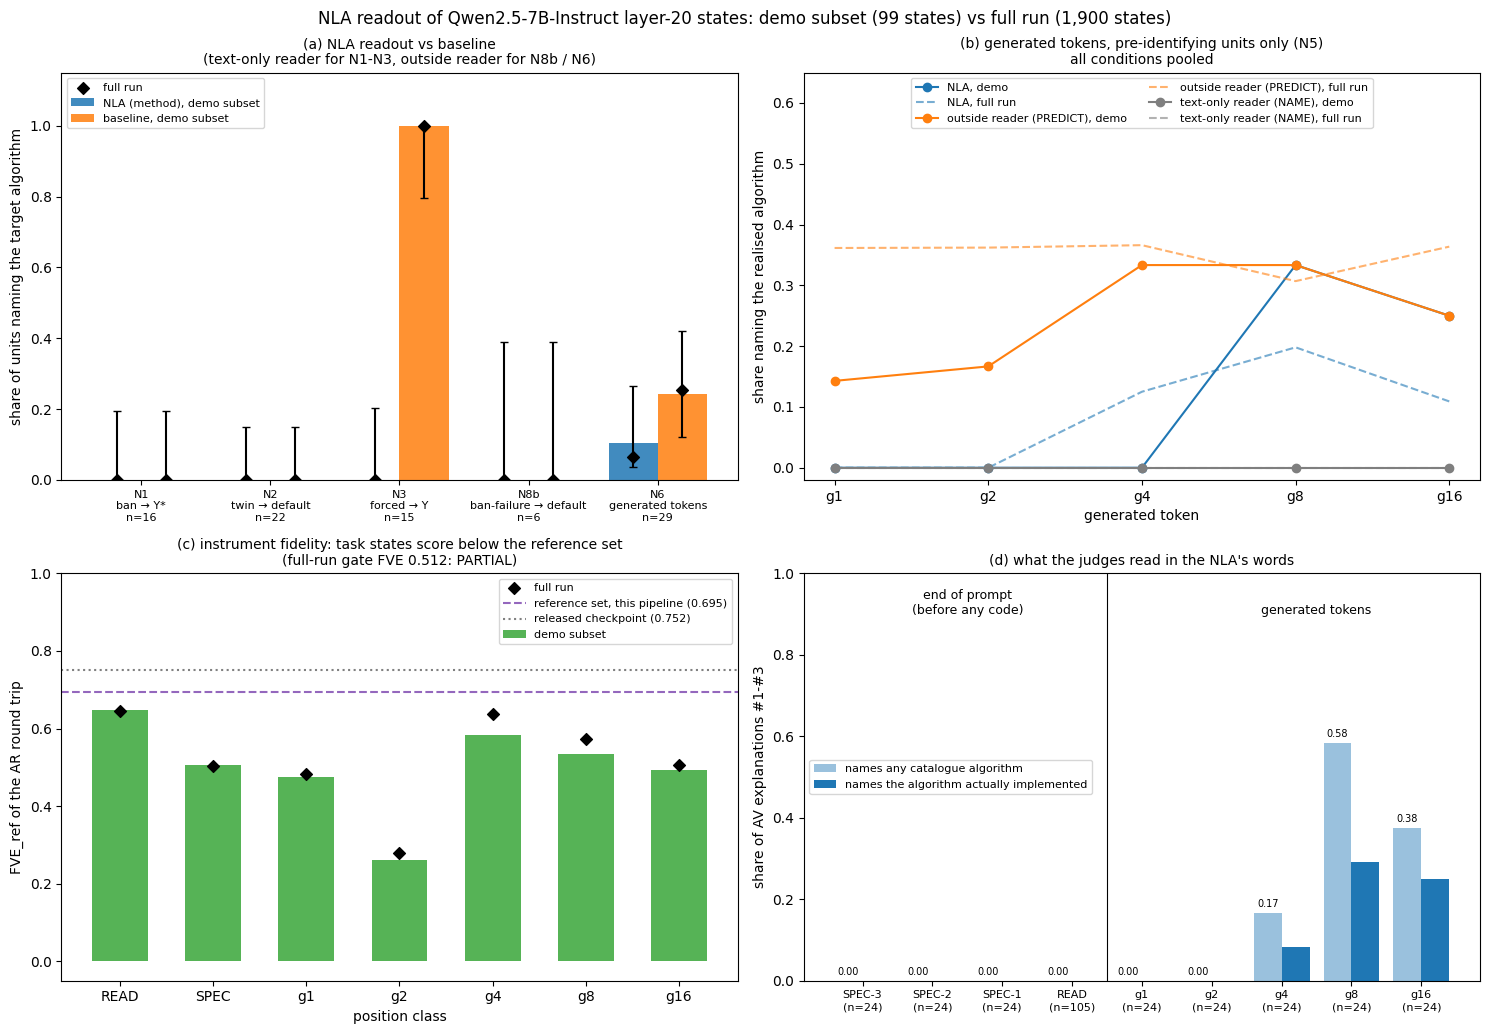

In [24]:
def _rate(r: dict[str, Any] | None) -> float:
    return np.nan if not r or r.get("rate") is None else r["rate"]


def _err(r: dict[str, Any] | None) -> tuple[float, float]:
    if not r or r.get("rate") is None:
        return (0.0, 0.0)
    return (max(0.0, r["rate"] - r["wilson95"][0]), max(0.0, r["wilson95"][1] - r["rate"]))  # clip float noise at 0/1


fig, axes = plt.subplots(2, 2, figsize=(15, 10.5))

# (a) method vs baseline on every paired test
ax = axes[0, 0]
tests = [("N1\nban → Y*", out["N1"], ref_t["N1"]),
         ("N2\ntwin → default", out["N2_default"], ref_t["N2_default"]),
         ("N3\nforced → Y", {"x_rate": n3_nla, "y_rate": n3_text}, {"mean_x": full_n3_nla, "mean_y": full_n3_text}),
         ("N8b\nban-failure → default", out["N8b_banfail_default_vs_predict"], ref_t["N8b_banfail_default_vs_predict"]),
         ("N6\ngenerated tokens", out["N6_per_sample"], ref_t["N6_per_sample"])]
xs = np.arange(len(tests))
for j, (key, fkey, colr, lab) in enumerate((("x_rate", "mean_x", "tab:blue", "NLA (method)"),
                                           ("y_rate", "mean_y", "tab:orange", "baseline"))):
    off = (j - 0.5) * 0.38
    ax.bar(xs + off, [_rate(m[key]) for _, m, _ in tests], 0.38, color=colr, alpha=0.85,
           yerr=np.array([_err(m[key]) for _, m, _ in tests]).T, capsize=3, label=f"{lab}, demo subset")
    ax.scatter(xs + off, [f[fkey] for _, _, f in tests], marker="D", color="black", zorder=3,
               label="full run" if j == 0 else None)
ax.set_xticks(xs, [f"{t}\nn={m['x_rate'].get('n', 0)}" for t, m, _ in tests], fontsize=8)
ax.set_ylim(0, 1.15)
ax.set_ylabel("share of units naming the target algorithm")
ax.set_title("(a) NLA readout vs baseline\n(text-only reader for N1-N3, outside reader for N8b / N6)", fontsize=10)
ax.legend(fontsize=8, loc="upper left")

# (b) generated tokens: who names the realised algorithm before the visible text identifies it
ax = axes[0, 1]
gs = (1, 2, 4, 8, 16)


def pool_curve(curves_: dict[str, Any], reader: str) -> list[float]:
    vals = []
    for g in gs:
        cells = [c[f"g{g}"][reader] for c in curves_.values() if f"g{g}" in c]
        k, n = sum(c["k"] for c in cells), sum(c["n"] for c in cells)
        vals.append(k / n if n else np.nan)
    return vals


for reader, colr, lab in (("nla", "tab:blue", "NLA"), ("text_predict", "tab:orange", "outside reader (PREDICT)"),
                          ("text_name", "tab:gray", "text-only reader (NAME)")):
    ax.plot(range(len(gs)), pool_curve(out["N5_gen"]["curves_pre_identifying"], reader), "o-", color=colr, label=f"{lab}, demo")
    ax.plot(range(len(gs)), pool_curve(ref["N5_gen"], reader), "--", color=colr, alpha=0.6, label=f"{lab}, full run")
ax.set_xticks(range(len(gs)), [f"g{g}" for g in gs])
ax.set_ylim(-0.02, 0.65)
ax.set_xlabel("generated token")
ax.set_ylabel("share naming the realised algorithm")
ax.set_title("(b) generated tokens, pre-identifying units only (N5)\nall conditions pooled", fontsize=10)
ax.legend(fontsize=8, ncol=2, loc="upper center")

# (c) instrument fidelity per position class
ax = axes[1, 0]
classes = ("READ", "SPEC", "g1", "g2", "g4", "g8", "g16")
demo_fve = [out["gate_fve_ref_by_class"].get(c, {}).get("fve_ref", np.nan) for c in classes]
xs = np.arange(len(classes))
ax.bar(xs, demo_fve, 0.6, color="tab:green", alpha=0.8, label="demo subset")
ax.scatter(xs, [gate["classes"][c]["fve_ref"] for c in classes], marker="D", color="black", zorder=3, label="full run")
ax.axhline(gate["reference"]["fve_ref"], ls="--", color="tab:purple",
           label=f"reference set, this pipeline ({gate['reference']['fve_ref']:.3f})")
ax.axhline(gate["pipeline_check"]["target"], ls=":", color="gray",
           label=f"released checkpoint ({gate['pipeline_check']['target']:.3f})")
ax.set_xticks(xs, classes)
ax.set_ylim(min(0.0, np.nanmin(demo_fve + [0.0]) - 0.05), 1)
ax.set_xlabel("position class")
ax.set_ylabel("FVE_ref of the AR round trip")
ax.set_title(f"(c) instrument fidelity: task states score below the reference set\n"
             f"(full-run gate FVE {gate['classes']['ALL']['fve_ref']:.3f}: {gate['verdict']})", fontsize=10)
ax.legend(fontsize=8)

# (d) what the explanations name, position by position
ax = axes[1, 1]
positions = ("SPEC-3", "SPEC-2", "SPEC-1", "READ", "g1", "g2", "g4", "g8", "g16")
any_named, implemented, n_expl = [], [], []
for pos in positions:
    ex_ = [(e["resolved"], r["output"]) for r in demo_rows if r["metadata_position"] == pos
           for e in json.loads(r["metadata_explanations"])[:3]]
    n_expl.append(len(ex_))
    any_named.append(np.mean([lab_ not in NAMED_EXCL for lab_, _ in ex_]) if ex_ else np.nan)
    implemented.append(np.mean([lab_ == o for lab_, o in ex_]) if ex_ else np.nan)
xs = np.arange(len(positions))
ax.bar(xs - 0.2, any_named, 0.4, color="tab:blue", alpha=0.45, label="names any catalogue algorithm")
ax.bar(xs + 0.2, implemented, 0.4, color="tab:blue", label="names the algorithm actually implemented")
for i, v in enumerate(any_named):
    if not np.isnan(v):
        ax.text(i - 0.2, v + 0.015, f"{v:.2f}", ha="center", fontsize=7)
ax.axvline(3.5, color="black", lw=0.8)
ax.text(1.5, 0.9, "end of prompt\n(before any code)", ha="center", fontsize=9)
ax.text(6.5, 0.9, "generated tokens", ha="center", fontsize=9)
ax.set_xticks(xs, [f"{p}\n(n={n})" for p, n in zip(positions, n_expl)], fontsize=8)
ax.set_ylim(0, 1)
ax.set_ylabel("share of AV explanations #1-#3")
ax.set_title("(d) what the judges read in the NLA's words", fontsize=10)
ax.legend(fontsize=8, loc="center left")

fig.suptitle(f"NLA readout of Qwen2.5-7B-Instruct layer-20 states: demo subset ({len(demo_rows)} states) "
             f"vs full run ({ref['n_readout_states']:,} states)", fontsize=12)
plt.tight_layout()
plt.show()

## 8. What the demo shows

- **Before any code exists, the NLA's words do not carry the planned algorithm.**
  - On the demo subset every end-of-prompt test is 0: N1 0/16 (the complete committed unit set, so this is the full-run result), N2 0/22, N8b 0/6.
  - The positive control fails too: the NLA names the requested algorithm in 0/15 forced states, while the text-only reader names it in 15/15.
  - The explanations describe the answer format ("a Python code block follows") and confabulate a different task: palindromes, prime numbers, top-k frequent elements.
- **The instrument is degraded, not broken.**
  - The round-trip FVE on these states is 0.54 on the subset and 0.51 in the full run. That is below the reference set's 0.695 but far from zero, and READ states keep 0.65.
  - The artifact's exploratory local control (not in this demo) explains the gap. Read *at* the algorithm-name token, the same NLA mentions the algorithm 80–89% of the time; the identity fades from the verbalisable part of the state within one sentence.
- **At later generated tokens (g4–g16) the NLA sometimes names the realised algorithm before the visible code does.** At g8 of a BFS-banned sample it says "A BFS maze solver", while the code so far is only `def solve(grid, start`.
  - Per sample, the outside reader, who sees only the prompt and the code prefix, is still right more often.
  - Demo: 7/29 vs 3/29, b:c = 2:6, p = 0.29. That is 8 samples drawn at random, too few for significance.
  - Full run: 92/364 vs 24/364, 20:88, p = 2e-11.
- **For the creativity question (can we read, and steer, the choice of algorithm?):**
  - With this layer-20 NLA the choice is not readable in words before the code starts, and the readout loses to simply reading the prompt.
  - In the artifact's causal arm (not part of this demo), the pre-registered verbal edits at the prompt positions fail on all four tasks.
  - Only exploratory, large pushes at the generated tokens steer two tasks: T06 to Floyd 0.76 vs 0.28, and T05 to brute force.
  - Plain prompting ("Implement Y", 0.90–1.00 adherence) remains the strongest knob.

To rerun the full experiment, set `RUN_PIPELINE = True` in a checkout of the artifact (a GPU of at least 22 GB, the three checkpoints and an `OPENROUTER_API_KEY`). To run the readout on more states, rebuild `mini_demo_data.json` with `build_mini_demo_data.py` from the artifact's `full_method_out.json`.